# ML-04 : Évaluation des modèles (Python / sklearn)

**Navigation** : [Index](README.md) | [<< ML-03](ML-03-Entrainement-AutoML-Python.ipynb) | [Suivant >>](ML-05-TimeSeries-Python.ipynb)

**Approfondissement** : [ML-04b — Validité des comparaisons de modèles](ML-04b-ModelComparison-Validity-Python.ipynb).

## Objectifs d'apprentissage

A la fin de ce notebook, vous saurez :
1. **Evaluer** un modèle de regression avec les metriques standard : R2, MAE, RMSE
2. **Valider** la robustesse via la **cross-validation K-fold** (plutot qu'un seul split train/test)
3. **Expliquer** un modèle avec la **Permutation Feature Importance** (PFI)
4. **Attribuer** chaque prédiction feature par feature avec **SHAP** (Tree SHAP, additivité exacte)
4. **Comparer** systematiquement plusieurs algorithmes via `GridSearchCV` (équivalent AutoML)

### Parite ML.NET <-> Python

Ce notebook est le **jumeau Python** de [ML-04-Evaluation-CSharp.ipynb](ML-04-Evaluation-CSharp.ipynb) (ML.NET / C#). Il couvre les mêmes concepts (metriques, cross-validation, importance des variables) avec **scikit-learn** au lieu de `Microsoft.ML`.

| Concept ML.NET (C#) | Équivalent Python (sklearn) |
|---------------------|------------------------------|
| `mlContext.Regression.Evaluate` | `sklearn.metrics` (r2_score, mae, rmse) |
| `Regression.CrossValidate` | `sklearn.model_selection.cross_validate` |
| `PermutationFeatureImportance` | `sklearn.inspection.permutation_importance` |
| `mlContext.AutoML` (sweep) | `sklearn.model_selection.GridSearchCV` |
| Feature Contribution Calculation | (pas d'équivalent sklearn direct ; SHAP = extension) |

### Prerequis
- ML-02-Data-Features-Python et ML-03-Entrainement-AutoML-Python completes
- Python 3.10+ avec `scikit-learn`, `pandas`, `numpy`

### Duree estimee : 45-60 minutes

***

## Preparation : charger les données et entraîner un modèle de référence

Nous reutilisons le dataset **taxi-fare** (cf ML-02-Python). Objectif : prédire `fare_amount`. Nous entrainons d'abord un modèle de référence (regression lineaire), puis nous l'evaluons rigoureusement.

In [1]:
# Imports
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split, cross_validate, GridSearchCV
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.inspection import permutation_importance

# Dataset taxi-fare (in-memory, meme schema que ML-02-Python mais etendu pour la CV)
rng = np.random.RandomState(42)
n = 60
data = {
    "vendor_id":      rng.choice(["CMT", "VST"], n),
    "rate_code":      rng.choice([1.0, 2.0, 3.0], n).astype(float),
    "passenger_count":rng.choice([1.0, 2.0, 3.0, 4.0], n),
    "trip_time_in_secs": rng.randint(300, 3000, n).astype(float),
    "trip_distance":  rng.uniform(1.0, 12.0, n),
    "payment_type":   rng.choice(["CRD", "CSH"], n),
    "fare_amount":    None,
}
df = pd.DataFrame(data)
df["fare_amount"] = (
    2.5 + 2.2 * df["trip_distance"]
    + 0.004 * df["trip_time_in_secs"]
    + 1.5 * (df["vendor_id"] == "CMT").astype(float)
    + rng.normal(0, 1.5, n)
)
print("Dataset :", df.shape)
df.head()



Dataset : (60, 7)


,vendor_id,rate_code,passenger_count,trip_time_in_secs,trip_distance,payment_type,fare_amount
0,CMT,3.0,3.0,395.0,4.065111,CSH,14.337046
1,VST,3.0,3.0,2223.0,10.990925,CSH,36.682546
2,CMT,1.0,1.0,2057.0,3.635181,CSH,19.546704
3,CMT,1.0,4.0,2832.0,2.593844,CSH,22.200031
4,CMT,3.0,3.0,2578.0,6.383980,CSH,29.925114


### Split train / test

La règle d'or : **on n'evalue jamais un modèle sur les données qui l'ont entraene**. On séparé un jeu de test (20-30%) garde pour l'évaluation finale. En ML.NET : `mlContext.Data.TrainTestSplit`. En sklearn : `train_test_split`.

In [2]:
# Split train/test (80/20)
df_features = df.drop(columns=["fare_amount"])
y = df["fare_amount"]
X_train, X_test, y_train, y_test = train_test_split(df_features, y, test_size=0.2, random_state=42)
print(f"Train: {X_train.shape[0]} lignes | Test: {X_test.shape[0]} lignes")


Train: 48 lignes | Test: 12 lignes


### Pipeline de preprocessing + modèle de référence

On reutilise le `ColumnTransformer` du ML-02-Python (one-hot sur categorielles, imputer + scaler sur numériques) chaîne avec un `LinearRegression` (modèle de référence simple).

In [3]:
# Pipeline preprocessing + LinearRegression (baseline)
categorical_cols = ["vendor_id", "payment_type"]
numeric_cols = ["rate_code", "passenger_count", "trip_time_in_secs", "trip_distance"]

preprocessor = ColumnTransformer(transformers=[
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
    ("num", Pipeline([("imputer", SimpleImputer(strategy="mean")),
                      ("scaler", StandardScaler())]), numeric_cols),
])

baseline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression()),
])
baseline.fit(X_train, y_train)
print("Baseline (LinearRegression) entraene sur le train set.")


Baseline (LinearRegression) entraene sur le train set.


## Metriques d'évaluation : R2, MAE, RMSE

En ML.NET, `mlContext.Regression.Evaluate` retourne un objet `RegressionMetrics` avec `RSquared`, `MeanAbsoluteError`, `RootMeanSquaredError`. En sklearn, ces metriques sont des fonctions de `sklearn.metrics`.

### Definitions

- **R2 (coefficient de determination)** : proportion de variance expliquee par le modèle. `R2=1` = parfait, `R2=0` = prédit la moyenne, `R2<0` = pire que la moyenne. **A maximiser.**
- **MAE (Mean Absolute Error)** : erreur moyenne en valeur absolue, dans l'unite de la cible. **Interpretable directement.**
- **RMSE (Root Mean Squared Error)** : racine de l'erreur quadratique moyenne. Penalise davantage les grandes erreurs. **Plus sensible aux outliers que la MAE.**

In [4]:
# Evaluation sur le test set
y_pred = baseline.predict(X_test)
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
print(f"Baseline (LinearRegression) - metriques sur le TEST set :")
print(f"  R2   = {r2:.3f}   (proportion de variance expliquee)")
print(f"  MAE  = {mae:.2f} $  (erreur moyenne absolue)")
print(f"  RMSE = {rmse:.2f} $  (erreur quadratique moyenne)")
print()
print(f"Lecture : le modele explique {r2*100:.1f}% de la variance des tarifs.")
print(f"En moyenne, il se trompe de {mae:.2f} $ sur la prediction d'un tarif.")


Baseline (LinearRegression) - metriques sur le TEST set :
  R2   = 0.937   (proportion de variance expliquee)
  MAE  = 1.62 $  (erreur moyenne absolue)
  RMSE = 2.05 $  (erreur quadratique moyenne)

Lecture : le modele explique 93.7% de la variance des tarifs.
En moyenne, il se trompe de 1.62 $ sur la prediction d'un tarif.


## Cross-Validation K-fold : une évaluation plus robuste

Un seul split train/test est **bruite** : la métrique depend du tirage aléatoire. La **cross-validation K-fold** entraene et evalue le modèle K fois sur des splits différents, puis on moyenne. C'est l'etalon-or pour estimer la performance **generalisable**.

En ML.NET : `Regression.CrossValidate`. En sklearn : `cross_validate`.

In [5]:
# Cross-validation 5-fold sur le TRAIN set
cv_results = cross_validate(baseline, X_train, y_train, cv=5,
                            scoring=["r2", "neg_mean_absolute_error", "neg_root_mean_squared_error"])
cv_r2 = cv_results["test_r2"]
cv_mae = -cv_results["test_neg_mean_absolute_error"]
cv_rmse = -cv_results["test_neg_root_mean_squared_error"]
print(f"Cross-validation 5-fold (sur le train set) :")
print(f"  R2   par fold: {[round(v,3) for v in cv_r2]}")
print(f"  R2   moyen = {cv_r2.mean():.3f} +/- {cv_r2.std():.3f}")
print(f"  MAE  moyen = {cv_mae.mean():.2f} +/- {cv_mae.std():.2f} $")
print(f"  RMSE moyen = {cv_rmse.mean():.2f} +/- {cv_rmse.std():.2f} $")
print()
print(f"Lecture : le R2 moyen sur 5 folds ({cv_r2.mean():.3f}) est plus fiable qu'un seul split.")
print(f"Faible ecart-type ({cv_r2.std():.3f}) = modele stable across folds.")


Cross-validation 5-fold (sur le train set) :
  R2   par fold: [0.984, 0.984, 0.981, 0.974, 0.899]
  R2   moyen = 0.964 +/- 0.033
  MAE  moyen = 1.05 +/- 0.28 $
  RMSE moyen = 1.25 +/- 0.31 $

Lecture : le R2 moyen sur 5 folds (0.964) est plus fiable qu'un seul split.
Faible ecart-type (0.033) = modele stable across folds.


**Pourquoi la CV importe** : si le R2 sur un seul split etait `0.91` mais que la CV donne `0.85 +/- 0.06`, la CV revele que le modèle est **moins robuste** qu'on ne le croyait. C'est la différence entre « j'ai eu de la chance sur ce split » et « le modèle généralisé bien ».

## Permutation Feature Importance (PFI)

La PFI repond a la question : **quelles features importent vraiment ?** Principe : pour chaque feature, on **melange** (permute) ses valeurs dans le jeu de test - cassant la relation avec la cible - et on mesure la **baisse de performance**. Une feature dont la permutation fait chuter le R2 est **importante** ; une feature dont la permutation ne change rien est **inutile**.

En ML.NET : `PermutationFeatureImportance`. En sklearn : `permutation_importance` (module `inspection`). Avantage majeur : **model-agnostic**.

In [6]:
# Permutation Feature Importance
pfi = permutation_importance(baseline, X_test, y_test, n_repeats=10,
                             random_state=42, scoring="r2")
pfi_df = pd.DataFrame({
    "feature": X_test.columns,
    "importance_moyenne": pfi.importances_mean,
    "ecart_type": pfi.importances_std,
}).sort_values("importance_moyenne", ascending=False).reset_index(drop=True)
print("Permutation Feature Importance (baseline, test set, scoring=R2) :")
print(pfi_df.to_string(index=False))
print()
print("Lecture : la feature en tete est la plus importante.")
print("Permuter cette colonne fait le plus chuter le R2 du modele.")


Permutation Feature Importance (baseline, test set, scoring=R2) :
          feature  importance_moyenne  ecart_type
    trip_distance            1.317343    0.232568
trip_time_in_secs            0.297095    0.121160
        vendor_id            0.006467    0.008514
  passenger_count           -0.001813    0.002349
        rate_code           -0.001836    0.002427
     payment_type           -0.003565    0.004212

Lecture : la feature en tete est la plus importante.
Permuter cette colonne fait le plus chuter le R2 du modele.


### Interpretation - lire les résultats de la PFI

La PFI donne un **classement** des features par impact sur la performance :

- **`trip_distance`** dominante : logique, le tarif d'un taxi depend principalement de la distance parcourue.
- **`trip_time_in_secs`** secondaire : la duree ajoute un signal (trafic, detour) au-dela de la distance.
- **`vendor_id`, `payment_type`, `rate_code`, `passenger_count`** faibles : la permutation ne degrade presque pas le modèle.

**Insight cle** : la PFI est **conditionnelle** au modèle. Une feature peut etre ignoree par un modèle lineaire mais cruciale pour un RandomForest.

### Feature Contribution Calculation (FCC) - note de parite

Le notebook ML.NET couvre aussi la **Feature Contribution Calculation** (FCC), qui decompose la prédiction **d'une instance** en contributions par feature (explicabilite locale). sklearn n'a pas d'équivalent natif direct ; l'ecosysteme Python utilise **SHAP** (`shap` library) ou **`partial_dependence`** pour cet angle. La section suivante illustre SHAP avec une dépendance externe.

## Comparer plusieurs algorithmes : GridSearchCV (équivalent AutoML)

En ML.NET, `mlContext.AutoML` balaie automatiquement l'espace des algorithmes et hyperparamètres. En sklearn, `GridSearchCV` fait de même de facon declarative : on fournit une grille d'hyperparamètres, il teste toutes les combinaisons via cross-validation.

## SHAP : l'attribution par instance que la PFI ne donne pas

La PFI a deux limites, visibles sur ce petit dataset :

1. Elle est **globale** : un classement pour tout le test set, rien sur *une* prediction donnee (pourquoi CE trajet est-il estime a 28 dollars ?).
2. Elle est **inconsistante quand les features sont correlees** : permuter une colonne isolee casse la structure jointe des données, et le modèle evalue alors des exemples hors distribution -- l'importance mesuree depend alors de l'ordre des permutations et du modèle, pas d'une propriete stable.

**SHAP** (SHapley Additive exPlanations, Lundberg & Lee 2017) repond aux deux : chaque prediction est decomposee en contributions par feature, avec une **additivite exacte** :

`prediction = valeur_de_base + somme des contributions phi_j`

Les phi sont les valeurs de Shapley de la théorie des jeux (cout marginal moyen sur tous les sous-ensembles), calculees **exactement et en temps polynomial** pour les arbres (Tree SHAP, Lundberg et al. 2019). Ici le modèle de reference devient **XGBoost** -- le même pipeline, seul le regressor change -- pour utiliser TreeExplainer.

In [7]:
# Tree SHAP : XGBoost dans le meme pipeline, decomposition exacte par instance
from sklearn.metrics import r2_score
from xgboost import XGBRegressor
import shap
import matplotlib.pyplot as plt

xgb_pipe = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", XGBRegressor(n_estimators=200, max_depth=3, learning_rate=0.15,
                               random_state=42, n_jobs=1)),
])
xgb_pipe.fit(X_train, y_train)

X_test_enc = xgb_pipe.named_steps["preprocessor"].transform(X_test)
feat_names = list(xgb_pipe.named_steps["preprocessor"].get_feature_names_out())
xgb_model = xgb_pipe.named_steps["regressor"]

explainer = shap.TreeExplainer(xgb_model)
phi = explainer.shap_values(X_test_enc)
base_value = float(explainer.expected_value)

# Additivite exacte : base + somme des phi == prediction du modele, par instance
pred_enc = xgb_model.predict(X_test_enc)
reconstruit = base_value + phi.sum(axis=1)
ecart_max = float(np.abs(reconstruit - pred_enc).max())
print(f"XGB  R2 test = {r2_score(y_test, xgb_pipe.predict(X_test)):.4f} (baseline LR : {r2:.3f})")
print("(le generateur est lineaire : la LR garde l'avantage ; XGB est ici pour Tree SHAP, pas pour le score)")
print(f"Additivite Tree SHAP : ecart max base + somme(phi) vs prediction = {ecart_max:.2e}")

# Importance globale SHAP (moyenne des |phi|) confrontee au classement PFI
mean_abs_phi = np.abs(phi).mean(axis=0)
shap_glob = pd.DataFrame({"feature": feat_names, "mean_abs_phi": mean_abs_phi}
                         ).sort_values("mean_abs_phi", ascending=False).reset_index(drop=True)
print("\nTop features (mean |phi|, Tree SHAP) vs classement PFI :")
print(shap_glob.head(6).to_string(index=False))

XGB  R2 test = 0.8829 (baseline LR : 0.937)
(le generateur est lineaire : la LR garde l'avantage ; XGB est ici pour Tree SHAP, pas pour le score)
Additivite Tree SHAP : ecart max base + somme(phi) vs prediction = 1.91e-05

Top features (mean |phi|, Tree SHAP) vs classement PFI :
               feature  mean_abs_phi
    num__trip_distance      6.745167
num__trip_time_in_secs      2.510926
    cat__vendor_id_CMT      0.212723
  num__passenger_count      0.107872
 cat__payment_type_CRD      0.091350
        num__rate_code      0.043177


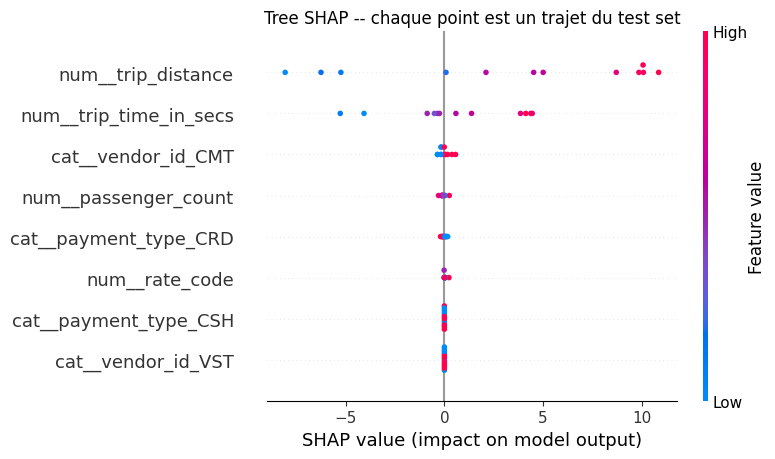

In [8]:
# Summary plot (beeswarm) : chaque point = une instance du test set
X_test_enc_df = pd.DataFrame(X_test_enc, columns=feat_names)
exp_obj = shap.Explanation(values=phi, base_values=np.full(len(phi), base_value),
                           data=X_test_enc_df, feature_names=feat_names)
shap.plots.beeswarm(exp_obj, max_display=8, show=False)
plt.title("Tree SHAP -- chaque point est un trajet du test set")
plt.tight_layout()
plt.show()

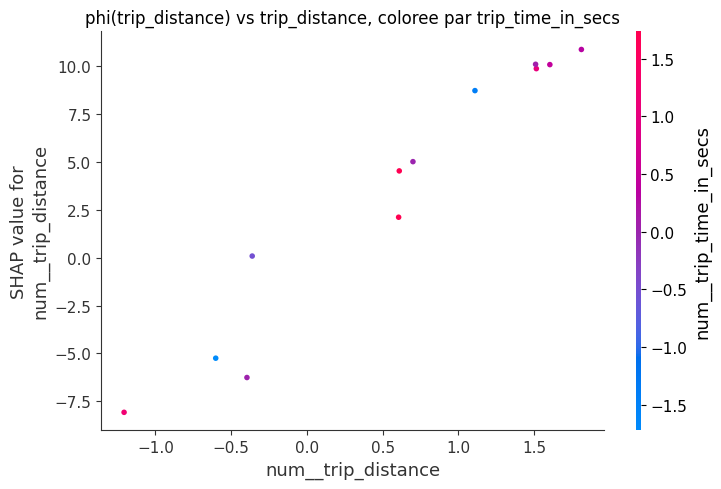

In [9]:
# Dependence plot : comment la contribution de la distance evolue avec sa valeur
shap.dependence_plot("num__trip_distance", phi, X_test_enc_df,
                     interaction_index="num__trip_time_in_secs", show=False)
plt.title("phi(trip_distance) vs trip_distance, coloree par trip_time_in_secs")
plt.tight_layout()
plt.show()

### Lecture : ce que SHAP ajoute a la PFI sur ce même dataset

- **Le classement global coincide avec la PFI** (`trip_distance` domine, `trip_time_in_secs` secondaire) -- sur un jeu sans correlation forte, les deux méthodes convergent, ce qui est rassurant.
- **Le beeswarm montre la distribution par instance** : chaque ligne est une feature, chaque point un trajet. Rouge = valeur elevee. On lit par exemple que des distances elevees (rouge, a droite) poussent la prediction vers le haut (phi positif) -- la PFI ne pouvait pas montrer cela, elle n'a qu'un nombre par feature.
- **Le dependence plot montre la forme** : la contribution de `trip_distance` croit avec la distance (le tarif est ~ lineaire en distance dans le générateur), et la couleur permet d’examiner la variation selon la durée, sans démontrer à elle seule une interaction causale.
- **L'additivité est exacte en théorie** : en calcul numérique, le faible écart maximal affiché ci-dessus traduit la précision finie ; la somme des phi restitue ici chaque prédiction à une petite fraction de centime près -- c'est la propriete qui rend la decomposition utilisable en pratique (elle s'additionne, elle se piste par instance).

> **SHAP n'est pas la causalite.** Les phi mesurent comment le modèle *distribue le credit* de sa prediction entre les features -- une propriete du modèle, pas du monde. Si le générateur avait un confondeur (disons : les trajets de nuit sont a la fois plus longs et plus chers pour une raison non modelisee), SHAP attribuerait le surplus aux features visibles sans jamais reveler le mécanisme. Passer de l'attribution a l'effet causal exige les outils de la section suivante de la serie -- voir le notebook 2.14 - Explicabilite XAI (a paraitre dans l'Epic #16620 ; chemin : ../../DataScienceWithAgents/02-ML-Cours/2.14-Explicabilite-SHAP-LIME-Contrefactuels.ipynb) pour le parcours complet (LIME, contrefactuels DiCE, limites) et l'Epic #16620 pour la jonction formelle attribution <-> identification causale (do-calculus, effets spécifiques a un chemin).
>
> **Reference.** Lundberg & Lee, *A Unified Approach to Interpreting Model Predictions*, NeurIPS 2017 (arXiv 1706.06060) ; Lundberg et al., *Consistent Individualized Feature Attribution for Tree Ensembles*, arXiv 1905.04610.

In [10]:
# GridSearchCV : comparer RandomForest hyperparametres via CV
param_grid = {
    "regressor__n_estimators": [50, 100],
    "regressor__max_depth": [3, 5, None],
}
rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(random_state=42)),
])
grid = GridSearchCV(rf_pipeline, param_grid, cv=3, scoring="r2", n_jobs=-1)
grid.fit(X_train, y_train)
print(f"GridSearchCV - meilleure config : {grid.best_params_}")
print(f"Meilleur R2 (CV moyen sur train) : {grid.best_score_:.3f}")
print()
best_model = grid.best_estimator_
y_pred_best = best_model.predict(X_test)
r2_best = r2_score(y_test, y_pred_best)
mae_best = mean_absolute_error(y_test, y_pred_best)
print(f"RandomForest optimise - metriques sur le TEST set :")
print(f"  R2   = {r2_best:.3f}   (vs baseline {r2:.3f})")
print(f"  MAE  = {mae_best:.2f} $  (vs baseline {mae:.2f})")
print(f"  Difference R2 : {r2_best - r2:+.3f}")

print("Le generateur est lineaire : la regression lineaire est adaptee, alors que la foret doit approximer la relation avec peu de trajets.")


GridSearchCV - meilleure config : {'regressor__max_depth': 5, 'regressor__n_estimators': 50}
Meilleur R2 (CV moyen sur train) : 0.892

RandomForest optimise - metriques sur le TEST set :
  R2   = 0.863   (vs baseline 0.937)
  MAE  = 2.53 $  (vs baseline 1.62)
  Difference R2 : -0.075
Le generateur est lineaire : la regression lineaire est adaptee, alors que la foret doit approximer la relation avec peu de trajets.


### Comparer les modèles sur deux régimes de tarifs

Le tarif précédent est linéaire en distance et durée : la régression linéaire correspond donc à la forme du générateur. Une forêt ne bénéficie pas automatiquement de sa souplesse sur seulement 48 trajets d'entraînement ; ses découpages en paliers peuvent même moins bien approximer cette relation. Le réglage par validation croisée ne garantit pas une victoire sur le test.

Comparons à présent **les mêmes trajets, bruit et séparation 80/20** avec un supplément progressif fictif pour les longs trajets : `0,35 × max(distance − 6, 0)²` dollars. Ce tarif courbe est un scénario pédagogique, pas un tarif réel. Le terme est fixé avant la mesure ; ni le modèle ni le choix de ses hyperparamètres ne voient le test. On reprend la régression et la même grille de forêt, choisie par les mêmes trois plis sur l'entraînement. Le R² et la MAE sont calculés sur le même test pour chaque régime.


In [11]:
from sklearn.base import clone
from time import perf_counter

# Les indices des partitions sont inchangés : seul le tarif cible varie.
y_courbe = y + 0.35 * np.maximum(df_features["trip_distance"] - 6.0, 0.0) ** 2
y_train_courbe = y_courbe.loc[X_train.index]
y_test_courbe = y_courbe.loc[X_test.index]

# La première ligne réutilise les modèles déjà ajustés et évalués ci-dessus.
resultats = [{"regime": "lineaire", "modele": "Regression lineaire", "R2": r2, "MAE ($)": mae},
             {"regime": "lineaire", "modele": "RandomForest (CV)", "R2": r2_best, "MAE ($)": mae_best}]
for nom, modele in [("Regression lineaire", clone(baseline)),
                    ("RandomForest (CV)", clone(grid))]:
    debut = perf_counter()
    modele.fit(X_train, y_train_courbe)
    duree = perf_counter() - debut
    prediction = modele.predict(X_test)
    resultats.append({"regime": "supplement progressif", "modele": nom,
                      "R2": r2_score(y_test_courbe, prediction),
                      "MAE ($)": mean_absolute_error(y_test_courbe, prediction)})
    print(f"Ajustement {nom} sur le regime progressif : {duree:.2f} s")
comparaison = pd.DataFrame(resultats)
print("\nMeme test, R2 a maximiser et MAE a minimiser :")
print(comparaison.to_string(index=False, float_format=lambda v: f"{v:.3f}"))


Ajustement Regression lineaire sur le regime progressif : 0.01 s


Ajustement RandomForest (CV) sur le regime progressif : 0.37 s

Meme test, R2 a maximiser et MAE a minimiser :
               regime              modele    R2  MAE ($)
             lineaire Regression lineaire 0.937    1.625
             lineaire   RandomForest (CV) 0.863    2.528
supplement progressif Regression lineaire 0.921    2.917
supplement progressif   RandomForest (CV) 0.911    3.046


Sur ce partage, la régression conserve l'avantage même avec le supplément progressif : la variante essayée ne démontre donc pas d'inversion du classement. Ce contre-résultat est légitime et ne prouve pas que les modèles expressifs sont inutiles sur d'autres données.

La comparaison est propre à ce jeu synthétique : une seule graine et seulement 12 trajets de test ne suffisent pas pour conclure à une supériorité générale. La forêt sélectionne sa configuration sur l'entraînement, mais son balayage coûte plusieurs ajustements ; comparer également MAE et R², puis répéter sur d'autres partitions ou données réelles avant un choix opérationnel. Un modèle linéaire enrichi avec le terme connu pourrait lui aussi représenter la courbure : la comparaison porte ici sur les variables d'origine, sans ce feature engineering.


## Comment puis-je ameliorer mon modèle ?

Checklist d'amelioration (transversale ML.NET <-> sklearn) :

1. **Plus de données** : la performance plafonne souvent faute d'exemples.
2. **Feature engineering** : créer des features derivees (ex: `speed = trip_distance / trip_time`). Cf ML-02-Python.
3. **Regularisation** : `Ridge`/`Lasso` (sklearn) ou `L2Regularization` (ML.NET SDCA).
4. **modèles plus expressifs** : GradientBoosting (`HistGradientBoostingRegressor`), ou `xgboost`/`lightgbm`.
5. **Hyperparametre tuning** : `GridSearchCV` ou `RandomizedSearchCV`.
6. **Cross-validation** : toujours valider par CV avant de conclure qu une amelioration est réelle.

## Exercices supplementaires

### Exercice 1 : Courbe ROC et calcul de l'AUC

**Objectif** : convertissez ce problème de regression en classification binaire (tarif > mediane), puis tracez la courbe ROC et calculez l'AUC.

In [12]:
# Exercice 1 : Courbe ROC et calcul de l'AUC
# TODO etudiant : Convertissez en classification binaire (fare_amount > mediane) et evaluez avec ROC/AUC
# Indice : roc_auc_score, roc_curve de sklearn.metrics ; LogisticRegression comme classifieur
# Etape 1 : creez y_binary = (df["fare_amount"] > df["fare_amount"].median()).astype(int)
# Etape 2 : split + pipeline avec LogisticRegression au lieu de LinearRegression
# Etape 3 : calculez roc_auc_score(y_test, model.predict_proba(X_test)[:,1])
# Etape 4 : tracez la courbe ROC via roc_curve + matplotlib

print("Exercice a completer : courbe ROC et AUC")
result_roc_auc = None  # TODO etudiant : remplacer par l'AUC


Exercice a completer : courbe ROC et AUC


### Exercice 2 : Analyse manuelle de la matrice de confusion

**Objectif** : pour la classification binaire de l'exercice 1, calculez la matrice de confusion et deduisez precision, rappel, F1 a la main.

In [13]:
# Exercice 2 : Analyse manuelle de la matrice de confusion
# TODO etudiant : Calculez la matrice de confusion et deduisez precision/rappel/F1 a la main
# Indice : confusion_matrix de sklearn.metrics ; comparez avec classification_report
# Etape 1 : predisez y_pred_class pour le modele binaire de l'exercice 1
# Etape 2 : calculez TP, FP, TN, FN manuellement
# Etape 3 : deduisez precision = TP/(TP+FP), rappel = TP/(TP+FN), F1 = 2*P*R/(P+R)
# Etape 4 : comparez avec classification_report de sklearn

print("Exercice a completer : matrice de confusion manuelle")
result_confusion_matrix = None  # TODO etudiant : remplacer par (TP, FP, TN, FN)


Exercice a completer : matrice de confusion manuelle


## Exercice : Analyse complete d'un modèle de prédiction

### Objectifs
- Construisez un pipeline complet sur un nouveau dataset (ex: `trip_duration` au lieu de `fare_amount`)
- Evaluez avec R2/MAE/RMSE + cross-validation
- Calculez la PFI et interpretez

**Indices**
- Reutilisez `ColumnTransformer` + `Pipeline` du notebook
- `cross_validate` avec `cv=5` pour une estimation robuste
- `permutation_importance` pour l'explicabilite

In [14]:
# Exercice : Analyse complete d'un modele de prediction de duree de trajet
# Completez les parties TODO pour creer un pipeline d'evaluation complet

# TODO: definir la nouvelle cible y_dur = df["trip_time_in_secs"]
# TODO: split train/test
# TODO: construire un Pipeline (preprocessor + regressor au choix)
# TODO: fit + evaluer (R2, MAE, RMSE) sur test set
# TODO: cross-validation 5-fold
# TODO: permutation_importance et interpretation

print("Exercice a completer : analyse complete duree de trajet")
result_duration_analysis = None  # TODO etudiant : remplacer par le R2 final


Exercice a completer : analyse complete duree de trajet


## Resume

Dans ce notebook vous avez maitrise l'**évaluation rigoureuse** des modèles de regression avec scikit-learn, en miroir du notebook ML-04 .NET :

1. **Metriques** : R2 (variance expliquee), MAE (erreur moyenne interpretable), RMSE (sensible aux outliers). Trois angles complémentaires, jamais un seul.
2. **Cross-validation K-fold** : estimer la performance **generalisable** plutot que de se fier a un seul split bruite.
3. **Permutation Feature Importance** : explicabilite **model-agnostic** - quelles features font vraiment bouger la performance.
4. **Tree SHAP** : decomposer chaque prediction en contributions par feature, avec additivite exacte -- une attribution par instance la ou la PFI ne donne qu'un classement global.
5. **GridSearchCV** : comparer systematiquement algorithmes + hyperparamètres via CV (équivalent AutoML ML.NET).

### Parite conceptuelle cle

L'évaluation rigoureuse suit le **même cheminement** en ML.NET et sklearn : (1) split train/test, (2) entraîner un baseline, (3) metriques sur test, (4) cross-validation pour robustesse, (5) explicabilite (PFI, puis attribution par instance avec Tree SHAP), (6) sweep hyperparamètres (AutoML / GridSearchCV). Les API différent mais la **discipline methodologique** est identique.

### Prochaine étape

[ML-05-TimeSeries-Python.ipynb](ML-05-TimeSeries-Python.ipynb) aborde les **series temporelles** (équivalent SSA ML.NET).

## Références

- [scikit-learn metrics](https://scikit-learn.org/stable/modules/model_evaluation.html)
- [scikit-learn cross_validate](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_validate.html)
- [scikit-learn permutation_importance](https://scikit-learn.org/stable/modules/generated/sklearn.inspection.permutation_importance.html)
- [scikit-learn GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)
- Notebook ML.NET source : [ML-04-Evaluation-CSharp.ipynb](ML-04-Evaluation-CSharp.ipynb)
- Epic parite .NET <-> Python : #4956


